# Politely — Rewriting Impolite Sentences with an Encoder–Decoder Built from Scratch

**NLP course project — Text generation with encoder–decoder architectures**
**Ikram Saidane** · November 2026

This notebook retraces the whole project, from the data to the final evaluation. Every step is
implemented here with explanations, so the notebook can be read on its own. The code is the same as
in the project files (`preprocessing.py`, `model.py`, `train.py`, `inference.py`, `evaluate.py`).

> **How to run it.** Open the notebook from the project folder (the one that contains `data/` and
> `checkpoints/`) and run all cells from top to bottom. It takes about 10 minutes on a CPU.
> Training the 8 models completely takes about 3 hours on a CPU. So, by default, the notebook runs a
> sanity check and a short training demonstration, then **reloads the models that were fully trained
> with the same code** (`checkpoints/`). To train models A, B and C completely inside the notebook,
> set `FULL_TRAINING = True` in section 14 (about 1 hour more).

**Link with the structure required by the assignment (and with the report)**

| Section of the assignment / report | Sections of this notebook |
|---|---|
| 1. Introduction | 1, 2 |
| 2. Related concepts | 2.1, 9, 10, 11 |
| 3. Dataset | 3, 4 |
| 4. Preprocessing | 5, 6, 7, 8 |
| 5. Proposed architecture | 9, 10, 11 |
| 6. Training | 12, 13, 14 |
| 7. Experimental results | 13, 17, 18 |
| 8. Generated examples | 15, 16, 19.2 |
| 9. Discussion | 19 |
| 10. Conclusion | 20 |

**Contents**

1. Project and objective
2. The NLP problem
3. The dataset
4. Data exploration
5. Preprocessing and text cleaning
6. Tokenisation and vocabulary
7. Numerical representation
8. Data preparation: padding, truncation, splits
9. The encoder–decoder architecture
10. Encoder and decoder
11. Attention and copy mechanism
12. Training
13. Loss curves
14. Saving and reloading the model
15. Generation on new inputs
16. Examples: input, expected output, generated output
17. Evaluation
18. Baseline vs improvements
19. Analysis of results, errors and limits
20. Conclusion

In [1]:
# Setup: libraries, paths and random seeds
import json
import math
import random
import re
import sys
import time
import unicodedata
from collections import Counter
from dataclasses import asdict, dataclass, fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

ROOT = Path.cwd()
DATA = ROOT / "data"
CKPT = ROOT / "checkpoints"
EXP = ROOT / "experiments"
REPORTS = ROOT / "reports"
assert (DATA / "train.csv").exists(), "Please open the notebook from the project folder."

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")

pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, ORANGE, RUST, GREY = "#176F63", "#E0A33A", "#B4532A", "#9AA3A0"
print("torch", torch.__version__, "| pandas", pd.__version__)

torch 2.15.0+cu132 | pandas 3.0.5


## 1. Project and objective

**Politely** takes a blunt, impatient or dismissive English sentence and generates a polite sentence
that says **the same thing**:

| Impolite input | Polite output |
|---|---|
| *Send me the report now.* | *Could you please send me the report as soon as possible?* |
| *You're wrong. Water boils at 100 degrees.* | *Actually, I think water boils at 100 degrees. Could you double-check?* |

The objective is to build and understand the **complete neural text-generation pipeline**:

`preprocessing → vocabulary → tokenisation → representation → encoder → decoder → training → generation → evaluation`

The model is an **encoder–decoder implemented with PyTorch and trained from scratch**. No pretrained
model (GPT, T5, BART…) and no API is used. Only standard components are used: `nn.Embedding`,
`nn.LSTM`, `nn.Linear`, the loss and the optimiser.

## 2. The NLP problem

This is a **paraphrase generation / text style transfer** task, formulated as a sequence-to-sequence
problem. Given an input sequence $x = (x_1, …, x_n)$ (impolite sentence), the model generates
$y = (y_1, …, y_m)$ (polite sentence) ending with `<EOS>`:

$$P(y \mid x) = \prod_{t=1}^{m} P(y_t \mid y_{<t}, x)$$

The model is trained to minimise the token-level cross-entropy. A good output must satisfy three
conditions at the same time:

1. **polite**: the tone changes;
2. **faithful**: the action, object, person, time and numbers of the input are kept;
3. **fluent**: correct English.

These three conditions guide the evaluation (section 17). The task is interesting for an
encoder–decoder because the output depends on the whole input (who, what, when must be kept) but its
*form* must change (order → question, criticism → softened feedback, refusal → apology…).

### 2.1 Related concepts

- **Encoder–decoder (sequence-to-sequence).** An **encoder** reads the input sequence and turns it
  into hidden representations. A **decoder** then generates the output one token at a time, each time
  conditioned on the previous tokens and on the encoder's representation. Input and output can have
  different lengths.
- **Recurrent networks (LSTM, GRU).** They read a sequence step by step and keep a hidden state.
  Their gates help them remember information over longer sequences than a simple RNN.
- **Attention** (Bahdanau et al., 2015). Instead of one fixed vector, the decoder computes, at each
  step, a weighted average of all the encoder states. It "looks" at the useful input words.
- **Copy mechanism / pointer-generator** (See et al., 2017). The decoder can copy a word of the input
  instead of generating it from the vocabulary. This is useful when the output must repeat parts of
  the input, as in our rewrites.

## 3. The dataset

### 3.1 Source

Public parallel corpora close to this task (for example ParaDetox) contain many insults and
offensive words. I wanted a **balanced** dataset with **no insult**, where both sides of a pair carry
exactly the same content, so I built the dataset for the project.

The program `data/generate_dataset.py` combines building blocks written by hand in
`data/resources.py`:
- situations, objects, people, times, facts;
- 108 impolite and 54 polite phrasings (templates) over 9 categories.

For each pair, the program:
1. chooses a *content* (an action and its object, a person, a time…);
2. writes it once with an impolite template, and 2 or 3 times with different polite templates.

So the impolite input and its polite references say exactly the same thing. Every sentence is
checked against a list of banned words, and the generation is reproducible (seed 42).

In [2]:
# The building blocks are in data/resources.py; the generator in data/generate_dataset.py
sys.path.insert(0, str(DATA))
import generate_dataset
import resources

tpl = resources.TEMPLATES["request"]
print("Some impolite templates of the 'request' category (id, text, held out?):")
for t in tpl["impolite"][:4]:
    print("  ", t)
print("\nSome polite templates of the same category:")
for t in tpl["polite"][:4]:
    print("  ", t)

Some impolite templates of the 'request' category (id, text, held out?):
   ('req_01', '{Base} {comp} {time}.', False)
   ('req_02', 'Just {base} {comp} {time}.', False)
   ('req_03', '{Base} {comp} {time}, and stop wasting my time.', False)
   ('req_04', 'I told you to {base} {comp}. Do it {time}.', False)

Some polite templates of the same category:
   Could you please {base} {comp} {ptime}?
   Would you mind {ing} {comp} {ptime}?
   When you have a moment, could you {base} {comp} {ptime}?
   I would really appreciate it if you could {base} {comp} {ptime}.


The generator is deterministic: running it again rebuilds **exactly** the dataset that is saved in
`data/`. Let me check it:

In [3]:
t0 = time.time()
rows = generate_dataset.generate(version=2)
regenerated = pd.DataFrame(rows)
saved_train = pd.read_csv(DATA / "train.csv", keep_default_na=False)
same = regenerated[regenerated.split == "train"][["impolite", "polite"]].reset_index(drop=True).equals(
    saved_train[["impolite", "polite"]])
print(f"{len(regenerated):,} pairs generated in {time.time() - t0:.1f} s — identical to data/train.csv: {same}")

39,600 pairs generated in 1.8 s — identical to data/train.csv: True


### 3.2 Size, fields and splits

Fields: **`impolite`** (input) → **`polite`** (target). Each row also has `id`, `split`,
`category`, `template_id` and `ref_index`. An impolite input has **2 polite references in train**
(2 training pairs), **3 in valid / test / test_unseen** and **1 in the hand-written challenge set**.
All the references are used by the metrics.

There are 5 splits:
- **train / valid / test**: same phrasings, but different contents. The splits are made *by
  content*, so a test sentence is never a training sentence;
- **test_unseen**: impolite phrasings that **never appear in training** (generalisation to new
  phrasings);
- **challenge**: 72 sentences **written by hand**, outside the generator (the hardest test).

In [4]:
SPLITS = ["train", "valid", "test", "test_unseen", "challenge"]
splits = {s: pd.read_csv(DATA / f"{s}.csv", keep_default_na=False) for s in SPLITS}
use = {"train": "training", "valid": "choosing the model / decoding", "test": "test (same phrasings)",
       "test_unseen": "test (new impolite phrasings)", "challenge": "test (written by hand)"}
pd.DataFrame([{"split": s, "pairs": len(df), "impolite inputs": df.impolite.nunique(),
               "references per input": round(len(df) / df.impolite.nunique(), 1), "used for": use[s]}
              for s, df in splits.items()])

,split,pairs,impolite inputs,references per input,used for
0,train,28800,14400,2.0,training
1,valid,4050,1350,3.0,choosing the model / decoding
2,test,4050,1350,3.0,test (same phrasings)
3,test_unseen,2700,900,3.0,test (new impolite phrasings)
4,challenge,72,72,1.0,test (written by hand)


In [5]:
# One example per category (training set)
train_df = splits["train"]
train_df.groupby("category").head(1)[["category", "impolite", "polite"]].reset_index(drop=True)

,category,impolite,polite
0,request,Turn on the TV this week.,Would you mind turning on the TV this week?
1,reminder,"Seriously, you were supposed to send the invoice to Diego. Send it before Monday. The deadline is Sunday.",I wanted to follow up: could you send the invoice to Diego before Monday? The deadline is Sunday.
2,refusal,Why would I lend you my magazines next week? No.,"I'd love to help, but I can't lend you my magazines next week this time."
3,criticism,Your logo for Sunday is so badly organized.,"I appreciate the effort on the logo for Sunday, but it is not very well organized."
4,complaint,Again! The wifi has not been working since yesterday.,"Hello, I wanted to let you know that my wifi has not been working since yesterday. Could you please look i..."
5,disagreement,Check your facts. The schedule has ten pages.,"Just to clarify, I think the schedule has ten pages."
6,question,Can I use the backpack on Saturday? Answer me.,"Excuse me, do you know whether I can use the backpack on Saturday?"
7,stop,Stop eating at your desk during calls. It disturbs the whole team.,"Would you mind not eating at your desk during calls, please? It disturbs the whole team."
8,announcement,The planning session will start one hour later on Saturday. Stop asking me about it.,"Unfortunately, the planning session will start one hour later on Saturday. Sorry for the inconvenience."


### 3.3 Improving the dataset (version 1 → version 2)

My **first version** (kept in `data_v1/`) had two problems:
- it only covered office life, with a vocabulary of 1,371 words;
- it contained incoherent pairs such as *"Move your car out of the library"* or
  *"Call Sarah back. Call it today."*.

The models trained on it reached only 0–1 % success on the sentences written by hand (rescored in
section 18.2 with the final metric). So I improved it:
I removed the incoherent pairs and widened the vocabulary to everyday life (home, shopping,
transport, school, leisure). The table below compares the two versions after the same preprocessing:

In [6]:
comp = json.loads((REPORTS / "dataset_v1_vs_v2.json").read_text())
pd.DataFrame({"version 1": comp["v1"], "version 2": comp["v2"]}).loc[
    ["vocab_size", "inputs", "pairs", "impolite_word_types", "challenge_unk_token_rate"]]

,version 1,version 2
vocab_size,1371.0000,1805.0000
inputs,10800.0000,14400.0000
pairs,21600.0000,28800.0000
impolite_word_types,1265.0000,1693.0000
challenge_unk_token_rate,0.1927,0.1146


With version 2, the share of unknown words in the hand-written sentences goes from 19 % to 11 %.

## 4. Data exploration

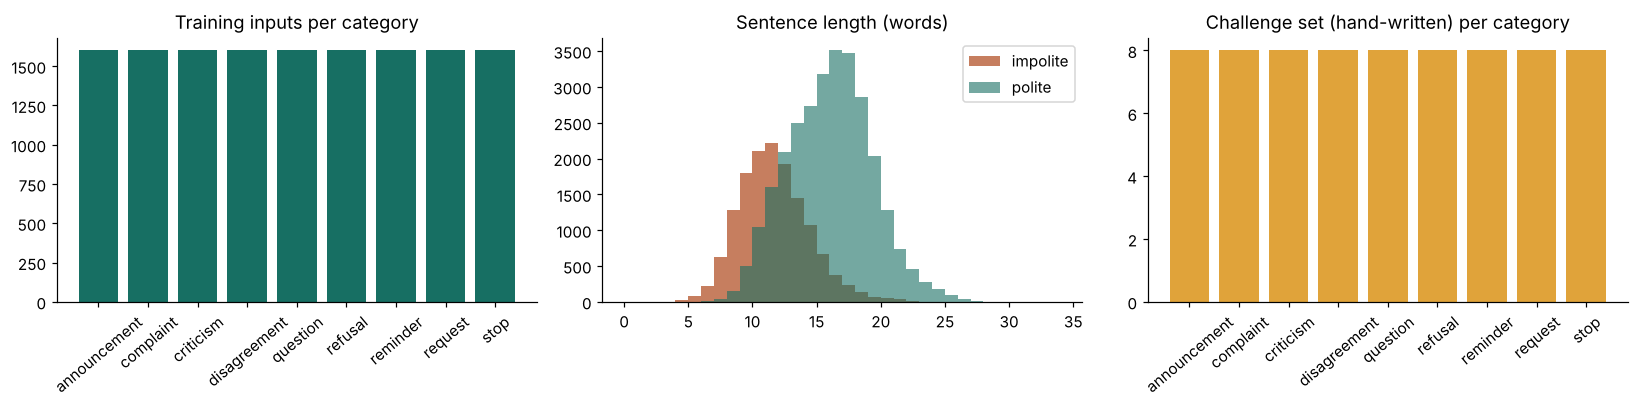

mean length: impolite 11.2 words, polite 15.6 words (polite sentences are longer: 'please', 'could you', 'thank you'...)


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
# category balance
counts = train_df.drop_duplicates("impolite").category.value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color=TEAL)
ax[0].set_title("Training inputs per category")
ax[0].tick_params(axis="x", rotation=40)
# sentence lengths (in words, simple split)
imp_len = train_df.drop_duplicates("impolite").impolite.str.split().str.len()
pol_len = train_df.polite.str.split().str.len()
ax[1].hist(imp_len, bins=range(0, 35), alpha=.75, color=RUST, label="impolite")
ax[1].hist(pol_len, bins=range(0, 35), alpha=.6, color=TEAL, label="polite")
ax[1].set_title("Sentence length (words)")
ax[1].legend()
# categories of the hand-written set
ch = splits["challenge"].category.value_counts().sort_index()
ax[2].bar(ch.index, ch.values, color=ORANGE)
ax[2].set_title("Challenge set (hand-written) per category")
ax[2].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()
print(f"mean length: impolite {imp_len.mean():.1f} words, polite {pol_len.mean():.1f} words "
      f"(polite sentences are longer: 'please', 'could you', 'thank you'...)")

In [8]:
# Quality checks: no sentence shared between two splits, no duplicate pair
inputs = {s: set(df.impolite) for s, df in splits.items()}
shared = {f"{a}/{b}": len(inputs[a] & inputs[b]) for i, a in enumerate(SPLITS) for b in SPLITS[i + 1:]}
print("impolite sentences shared between splits:", sum(shared.values()))
print("duplicate pairs:", sum(df.duplicated(["impolite", "polite"]).sum() for df in splits.values()))
print("pairs where input == output:", sum((df.impolite == df.polite).sum() for df in splits.values()))

impolite sentences shared between splits: 0
duplicate pairs: 0
pairs where input == output: 0


In [9]:
# The most frequent first words show the typical impolite and polite openings
first_imp = Counter(s.split()[0].strip(",.!?").lower() for s in train_df.drop_duplicates("impolite").impolite)
first_pol = Counter(s.split()[0].strip(",.!?").lower() for s in train_df.polite)
pd.DataFrame({"impolite: first word": [f"{w} ({c})" for w, c in first_imp.most_common(8)],
              "polite: first word": [f"{w} ({c})" for w, c in first_pol.most_common(8)]})

,impolite: first word,polite: first word
0,the (1235),i (5045)
1,i (877),could (3938)
2,i'm (736),would (2677)
3,no (693),i'm (2363)
4,stop (534),sorry (2264)
5,what (402),just (1762)
6,how (394),unfortunately (1076)
7,why (386),thanks (1076)


The dataset is perfectly balanced between the 9 categories. Polite sentences are longer, and they
often start with *I*, *could*, *would* or *sorry*. Impolite ones start directly with the subject
(*the…*, *I'm…*) or with blunt words such as *no*, *stop*, *what*, *why*. No sentence is shared between splits, so the test results really measure generalisation.

## 5. Preprocessing and text cleaning

| Step | Why it is needed here |
|---|---|
| Unicode normalisation (NFKC, curly quotes → simple quotes) | the same character always gives the same token (`don’t` = `don't`) |
| Lowercasing | politeness does not depend on case; *Could* and *could* become one word, so the model has fewer words to learn. Case is restored only for display |
| Spaces cleaned | no empty tokens |
| Punctuation kept as separate tokens | `?` matters a lot: polite requests are usually questions |
| Contractions kept as one token (*don't*, *I'm*) | they are frequent in impolite sentences and short to generate |

In [10]:
QUOTES = str.maketrans({"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-"})
TOKEN_RE = re.compile(r"\w+(?:'\w+)?|[^\w\s]")   # a word (with its contraction) or one punctuation mark


def normalize(text):
    text = unicodedata.normalize("NFKC", str(text)).translate(QUOTES).lower()
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text):
    return TOKEN_RE.findall(normalize(text))


def detokenize(tokens, capitalize=False):
    text = " ".join(tokens)
    text = re.sub(r" ([.,!?;:%)\]}])", r"\1", text)
    text = re.sub(r"([(\[{$]) ", r"\1", text)
    if capitalize:   # only for display
        text = re.sub(r"(\w) - (\w)", r"\1-\2", text)
        text = re.sub(r"\bi\b", "I", text)
        text = re.sub(r"\bi'(m|d|ll|ve)\b", lambda m: "I'" + m.group(1), text)
        text = re.sub(r"(^|[.!?]\s+)([a-z])", lambda m: m.group(1) + m.group(2).upper(), text)
    return text


for s in ["Send me the Report NOW!", "Don’t touch my laptop,   seriously.", "Why isn't the order #4521 here?"]:
    print(f"{s!r:45} -> {tokenize(s)}")
print(detokenize(["could", "you", "help", "me", "?"], capitalize=True))

'Send me the Report NOW!'                     -> ['send', 'me', 'the', 'report', 'now', '!']
'Don’t touch my laptop,   seriously.'         -> ["don't", 'touch', 'my', 'laptop', ',', 'seriously', '.']
"Why isn't the order #4521 here?"             -> ['why', "isn't", 'the', 'order', '#', '4521', 'here', '?']
Could you help me?


## 6. Tokenisation and vocabulary

The tokenisation is done at the **word level** with the regular expression above: a token is a word
(with its contraction) or a punctuation mark. Word level is simple and works well for short English
sentences.

The **vocabulary** is built **on the training set only**, so no information from the validation or
test sets leaks into the model. I keep the words seen **at least 2 times**, because a word seen once
cannot be learned well. Encoder and decoder share the same vocabulary, since both sides are English.
The special tokens have fixed ids:

| Token | Id | Role |
|---|---|---|
| `<PAD>` | 0 | fills short sentences in a batch; ignored by the encoder, the attention and the loss |
| `<SOS>` | 1 | first input of the decoder ("start writing") |
| `<EOS>` | 2 | end of the sentence: the decoder stops when it generates it |
| `<UNK>` | 3 | any word that is not in the vocabulary |

In [11]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
SPECIALS = ["<PAD>", "<SOS>", "<EOS>", "<UNK>"]


class Vocab:
    def __init__(self, itos):
        self.itos = list(itos)                                 # id -> word
        self.stoi = {w: i for i, w in enumerate(self.itos)}    # word -> id

    @classmethod
    def build(cls, token_lists, min_freq=2):
        counts = Counter(tok for toks in token_lists for tok in toks)
        words = sorted((w for w, c in counts.items() if c >= min_freq and w not in SPECIALS),
                       key=lambda w: (-counts[w], w))          # most frequent first
        return cls(SPECIALS + words)

    def __len__(self):
        return len(self.itos)

    def __contains__(self, word):
        return word in self.stoi

    def encode(self, tokens, add_sos=False, add_eos=False):
        ids = [self.stoi.get(t, UNK) for t in tokens]
        return ([SOS] if add_sos else []) + ids + ([EOS] if add_eos else [])

    def decode(self, ids, oovs=None):
        # stops at <EOS>; ids >= len(vocab) are input words copied by the copy mechanism
        out = []
        for i in map(int, ids):
            if i == EOS:
                break
            if i in (PAD, SOS):
                continue
            if i < len(self.itos):
                out.append(self.itos[i])
            elif oovs and i - len(self.itos) < len(oovs):
                out.append(oovs[i - len(self.itos)])
            else:
                out.append("<UNK>")
        return out


# each impolite input appears twice in train (2 references): it is counted once
train_sentences = [tokenize(x) for x in train_df.impolite.drop_duplicates()] + [tokenize(x) for x in train_df.polite]
vocab = Vocab.build(train_sentences, min_freq=2)
print("vocabulary size:", len(vocab))
print("first entries:", vocab.itos[:20])
saved_vocab = json.loads((DATA / "vocab.json").read_text())
print("identical to data/vocab.json (used by the trained models):", vocab.itos == saved_vocab)

vocabulary size: 1805
first entries: ['<PAD>', '<SOS>', '<EOS>', '<UNK>', 'the', '.', 'you', ',', 'to', 'i', '?', 'for', 'could', 'is', 'it', 'on', 'my', 'a', 'me', 'but']
identical to data/vocab.json (used by the trained models): True


In [12]:
# How many words of each split are unknown (<UNK>)?
def unk_rate(token_lists):
    total = sum(len(t) for t in token_lists)
    return sum(w not in vocab for t in token_lists for w in t) / total


pd.DataFrame([{"split": s, "unknown input tokens": round(unk_rate([tokenize(x) for x in df.impolite.drop_duplicates()]), 4),
               "inputs with ≥ 1 unknown word": round(np.mean([any(w not in vocab for w in tokenize(x))
                                                               for x in df.impolite.drop_duplicates()]), 3)}
              for s, df in splits.items()])

,split,unknown input tokens,inputs with ≥ 1 unknown word
0,train,0.0000,0.000
1,valid,0.0048,0.064
2,test,0.0050,0.067
3,test_unseen,0.0470,0.501
4,challenge,0.1146,0.639


Almost no word is unknown in train/valid/test. In `test_unseen` and in the hand-written `challenge`
set, many sentences contain at least one unknown word, often names, numbers or rare objects. This is
why the **copy mechanism** (section 11) matters: it lets the model copy such words even though it
cannot generate them.

## 7. Numerical representation

Each sentence becomes a list of ids. The decoder target is surrounded by `<SOS>` and `<EOS>`. Then
an embedding layer turns each id into a dense vector of dimension **128**, learned during training.

In [13]:
example = "Close the window now."
toks = tokenize(example)
print("text:   ", example)
print("tokens: ", toks)
print("ids:    ", vocab.encode(toks, add_eos=True))
target = "Would you mind closing the window as soon as possible?"
print("target ids (decoder):", vocab.encode(tokenize(target), add_sos=True, add_eos=True))

emb = nn.Embedding(len(vocab), 128, padding_idx=PAD)
vectors = emb(torch.tensor(vocab.encode(toks)))
print("after the embedding layer:", tuple(vectors.shape), "-> one 128-dimensional vector per token")

text:    Close the window now.
tokens:  ['close', 'the', 'window', 'now', '.']
ids:     [390, 4, 573, 58, 5, 2]
target ids (decoder): [1, 27, 6, 50, 1274, 4, 573, 43, 170, 43, 64, 10, 2]
after the embedding layer: (5, 128) -> one 128-dimensional vector per token


**Unknown words and the copy mechanism.** For model C, each input word that is not in the vocabulary
gets a *temporary* id `len(vocab) + k`, valid only for this sentence ("extended" ids). The model can
then point to it and copy it into the output:

In [14]:
def extended_ids(src_tokens, tgt_tokens, vocab):
    oovs, src_ext = [], []
    for t in src_tokens:
        if t in vocab:
            src_ext.append(vocab.stoi[t])
        else:
            if t not in oovs:
                oovs.append(t)
            src_ext.append(len(vocab) + oovs.index(t))
    tgt_ext = None
    if tgt_tokens is not None:
        tgt_ext = [SOS]
        for t in tgt_tokens:
            if t in vocab:
                tgt_ext.append(vocab.stoi[t])
            elif t in oovs:
                tgt_ext.append(len(vocab) + oovs.index(t))
            else:
                tgt_ext.append(UNK)
        tgt_ext.append(EOS)
    return src_ext, tgt_ext, oovs


src = tokenize("Where is my parcel 4521, Zorglub?")
src_ext, _, oovs = extended_ids(src, None, vocab)
print("tokens:          ", src)
print("normal ids:      ", vocab.encode(src), " (unknown words -> 3 = <UNK>)")
print("extended ids:    ", src_ext, " oovs =", oovs)

tokens:           ['where', 'is', 'my', 'parcel', '4521', ',', 'zorglub', '?']
normal ids:       [165, 13, 16, 362, 3, 7, 3, 10]  (unknown words -> 3 = <UNK>)
extended ids:     [165, 13, 16, 362, 1805, 7, 1806, 10]  oovs = ['4521', 'zorglub']


## 8. Data preparation: padding, truncation and splits

- **Splits**: already made when the dataset was built (section 3.2): train for learning, valid for
  choosing the model, epochs and decoding, and three test sets.
- **Truncation** at 40 tokens. No sentence of the dataset is longer (the longest has 31 tokens), so
  this is only a safety limit, also used by the interface.
- **Padding**: in a batch, all sentences get the length of the longest one, filled with `<PAD>` = 0.
  The real lengths are kept, so the encoder skips the padding (*packing*) and the attention and the
  loss ignore it (masks).

In [15]:
MAX_LEN = 40


def encode_example(src_tokens, tgt_tokens, vocab):
    src_ext, tgt_ext, oovs = extended_ids(src_tokens, tgt_tokens, vocab)
    ex = {"src": vocab.encode(src_tokens), "src_ext": src_ext, "oovs": oovs}
    if tgt_tokens is not None:
        ex["tgt"] = vocab.encode(tgt_tokens, add_sos=True, add_eos=True)
        ex["tgt_ext"] = tgt_ext
    return ex


class PairDataset(Dataset):
    def __init__(self, df, vocab, max_len=MAX_LEN):
        self.examples = [encode_example(tokenize(s)[:max_len], tokenize(t)[:max_len], vocab)
                         for s, t in zip(df["impolite"], df["polite"])]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        return self.examples[i]


def collate(batch):
    def pad(key):
        return pad_sequence([torch.tensor(ex[key]) for ex in batch], batch_first=True, padding_value=PAD)
    out = {"src": pad("src"), "src_ext": pad("src_ext"),
           "src_len": torch.tensor([len(ex["src"]) for ex in batch]),
           "oovs": [ex["oovs"] for ex in batch], "max_oov": max(len(ex["oovs"]) for ex in batch)}
    if "tgt" in batch[0]:
        out["tgt"], out["tgt_ext"] = pad("tgt"), pad("tgt_ext")
    return out


def make_loader(df, vocab, batch_size=64, shuffle=False, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(PairDataset(df, vocab), batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=g)


print("longest sentence in all splits:", max(len(tokenize(x)) for df in splits.values() for x in pd.concat([df.impolite, df.polite])), "tokens")
batch = next(iter(make_loader(train_df.head(4), vocab, batch_size=4)))
print("src", tuple(batch["src"].shape), "| tgt", tuple(batch["tgt"].shape), "| real lengths", batch["src_len"].tolist())
print(batch["src"])

longest sentence in all splits: 31 tokens
src (4, 16) | tgt (4, 17) | real lengths [7, 7, 16, 16]
tensor([[259,  15,   4, 702,  23,  48,   5,   0,   0,   0,   0,   0,   0,   0,
           0,   0],
        [259,  15,   4, 702,  23,  48,   5,   0,   0,   0,   0,   0,   0,   0,
           0,   0],
        [137, 368, 493,  55,   9,  36,   8, 111,  10, 822,   4, 714,  57, 180,
          79,   5],
        [137, 368, 493,  55,   9,  36,   8, 111,  10, 822,   4, 714,  57, 180,
          79,   5]])


## 9. The encoder–decoder architecture

I started from the baseline suggested in the assignment and added two improvements:

```
           input ids
               │ Embedding (128, shared with the decoder)
               ▼
        LSTM encoder (1 layer, unidirectional, hidden 256) ──► one state h_j per input word
               │ final state = representation of the sentence
               ▼
 <SOS> ──► LSTM decoder (hidden 256) ◄── context vector (attention over the h_j)   [model B]
               │
        Linear → softmax over the vocabulary  (+ copy of input words)               [model C]
               │
        next word … until <EOS>
```

| Model | What changes |
|---|---|
| **A** | baseline: LSTM encoder–decoder, no attention: the decoder only receives the final state of the encoder |
| **B** | A + **Bahdanau attention** |
| **C** | B + **copy mechanism** (pointer-generator) → final model |
| C', D, E, F | variants of B/C: word dropout, GRU cells, hidden size 128 / 512, teacher forcing 0.5 |

All models use the same classes; only the configuration changes.

In [16]:
@dataclass
class Config:
    name: str = "A_lstm"
    rnn_type: str = "lstm"      # "lstm" or "gru"
    emb_dim: int = 128          # embedding dimension
    hid_dim: int = 256          # hidden dimension
    dropout: float = 0.3
    attention: bool = False     # model B
    copy: bool = False          # model C
    attn_dim: int = 128
    min_freq: int = 2
    max_len: int = 40
    max_decode_len: int = 40    # stopping criterion if <EOS> never comes
    batch_size: int = 64
    lr: float = 1e-3
    clip: float = 1.0
    tf_ratio: float = 1.0       # teacher forcing ratio
    epochs: int = 30
    patience: int = 3           # early stopping
    lr_patience: int = 1
    lr_factor: float = 0.5
    seed: int = 42
    unk_dropout: float = 0.0

    @classmethod
    def from_dict(cls, d):
        names = {f.name for f in fields(cls)}
        return cls(**{k: v for k, v in d.items() if k in names})


configs = {name: Config.from_dict(json.loads((ROOT / "configs" / f"{name}.json").read_text()))
           for name in ["A_lstm", "B_attention", "C_copy_nodrop"]}
pd.DataFrame([asdict(c) for c in configs.values()]).set_index("name")[
    ["rnn_type", "emb_dim", "hid_dim", "attention", "copy", "dropout", "batch_size", "lr", "tf_ratio"]]

,rnn_type,emb_dim,hid_dim,attention,copy,dropout,batch_size,lr,tf_ratio
name,,,,,,,,,
A_lstm,lstm,128,256,False,False,0.3,64,0.001,1.0
B_attention,lstm,128,256,True,False,0.3,64,0.001,1.0
C_copy_nodrop,lstm,128,256,True,True,0.3,64,0.001,1.0


## 10. Encoder and decoder

**Encoder.** It receives the padded ids, turns them into embeddings and reads them with an LSTM
(1 layer, unidirectional, hidden 256). *Packing* gives the real lengths to the LSTM, so it ignores
`<PAD>`. It returns:
- `out`: one hidden state per input word (used by the attention);
- `state`: the final state $(h, c)$, which summarises the sentence. It is the **initial state of the
  decoder**.

**Decoder.** It generates the output **one word at a time**:
- **input at each step**: the embedding of the previous word (`<SOS>` at the first step), plus the
  context vector with attention;
- the LSTM updates its state;
- the output layer is a linear layer on [decoder state; previous word; context], followed by a
  linear layer of the vocabulary size and a softmax, which gives a probability for each of the 1,805
  words;
- **stopping criterion**: the decoder stops when it generates `<EOS>`, or after 40 words.

In [17]:
RNN = {"lstm": nn.LSTM, "gru": nn.GRU}


def last_hidden(state):
    h = state[0] if isinstance(state, tuple) else state   # LSTM: (h, c) — GRU: h
    return h[-1]


class Encoder(nn.Module):
    def __init__(self, embedding, cfg):
        super().__init__()
        self.embedding = embedding
        self.rnn = RNN[cfg.rnn_type](cfg.emb_dim, cfg.hid_dim, batch_first=True)
        self.dropout = nn.Dropout(cfg.dropout)

    def forward(self, src, src_len):
        emb = self.dropout(self.embedding(src))                                   # [B, S, 128]
        packed = pack_padded_sequence(emb, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, state = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))   # [B, S, 256]
        return out, state

## 11. Attention and copy mechanism

**Why attention?** Without attention (model A), the decoder only receives the final state of the
encoder: one vector of 256 numbers must summarise the whole sentence, and details get lost (names,
objects, times). With **Bahdanau (additive) attention**, at each step the decoder looks at **all**
the encoder states:

1. **scores**: $e_j = v^\top \tanh(W_{enc} h_j + W_{dec} s)$, where $h_j$ is the state of input word
   $j$ and $s$ the current decoder state. Padding gets $-\infty$;
2. **weights**: $\alpha = \text{softmax}(e)$. They are positive and sum to 1;
3. **context vector**: $c = \sum_j \alpha_j h_j$, a weighted average of the encoder states;
4. the context is given to the decoder LSTM (with the previous word) and to the output layer.

**Copy mechanism (model C).** Many words must be copied as they are (objects, names, numbers). A
switch $p_{gen} = \sigma(w \cdot [c; s; e])$ mixes two distributions:

$$P(w) = p_{gen} \, P_{vocab}(w) + (1 - p_{gen}) \sum_{j: x_j = w} \alpha_j$$

The model can therefore *copy* an input word using the attention weights, even if it is not in the
vocabulary.

In [18]:
class BahdanauAttention(nn.Module):
    def __init__(self, enc_dim, dec_dim, attn_dim):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, attn_dim, bias=False)
        self.W_dec = nn.Linear(dec_dim, attn_dim)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def project_keys(self, enc_out):          # W_enc h_j: computed once per sentence
        return self.W_enc(enc_out)

    def forward(self, dec_h, keys, enc_out, mask):
        scores = self.v(torch.tanh(keys + self.W_dec(dec_h).unsqueeze(1))).squeeze(-1)   # [B, S]
        scores = scores.masked_fill(~mask, float("-inf"))                                # ignore <PAD>
        weights = torch.softmax(scores, dim=-1)                                          # sum to 1
        context = torch.bmm(weights.unsqueeze(1), enc_out).squeeze(1)                    # [B, 256]
        return context, weights


class Decoder(nn.Module):
    def __init__(self, embedding, vocab_size, cfg):
        super().__init__()
        self.embedding, self.cfg = embedding, cfg
        ctx = cfg.hid_dim if cfg.attention else 0
        if cfg.attention:
            self.attention = BahdanauAttention(cfg.hid_dim, cfg.hid_dim, cfg.attn_dim)
        self.rnn = RNN[cfg.rnn_type](cfg.emb_dim + ctx, cfg.hid_dim, batch_first=True)
        self.pre_out = nn.Linear(cfg.hid_dim + ctx + cfg.emb_dim, cfg.emb_dim)
        self.out = nn.Linear(cfg.emb_dim, vocab_size)
        if cfg.copy:
            self.p_gen = nn.Linear(ctx + cfg.hid_dim + cfg.emb_dim, 1)
        self.dropout = nn.Dropout(cfg.dropout)

    def step(self, inp, state, enc_out=None, keys=None, mask=None, src_ext=None, max_oov=0):
        """One decoding step: previous word -> log-probabilities of the next word."""
        emb = self.dropout(self.embedding(inp))
        weights = p_gen = None
        if self.cfg.attention:
            context, weights = self.attention(last_hidden(state), keys, enc_out, mask)
            rnn_in = torch.cat([emb, context], dim=-1)
        else:
            rnn_in = emb
        out, state = self.rnn(rnn_in.unsqueeze(1), state)
        s = out.squeeze(1)
        feats = [s, emb] + ([context] if self.cfg.attention else [])
        logits = self.out(self.dropout(self.pre_out(torch.cat(feats, dim=-1))))
        if not self.cfg.copy:
            return F.log_softmax(logits, dim=-1), state, weights, None
        # copy mechanism: mix "generate from the vocabulary" and "copy from the input"
        p_gen = torch.sigmoid(self.p_gen(torch.cat([context, s, emb], dim=-1)))
        dist = p_gen * torch.softmax(logits, dim=-1)
        if max_oov > 0:
            dist = torch.cat([dist, dist.new_zeros(dist.size(0), max_oov)], dim=1)
        dist = dist.scatter_add(1, src_ext, (1 - p_gen) * weights)
        return torch.log(dist + 1e-12), state, weights, p_gen


class Seq2Seq(nn.Module):
    def __init__(self, cfg, vocab_size):
        super().__init__()
        self.cfg, self.vocab_size = cfg, vocab_size
        self.embedding = nn.Embedding(vocab_size, cfg.emb_dim, padding_idx=PAD)   # shared
        self.encoder = Encoder(self.embedding, cfg)
        self.decoder = Decoder(self.embedding, vocab_size, cfg)

    def encode(self, src, src_len):
        enc_out, state = self.encoder(src, src_len)
        keys = self.decoder.attention.project_keys(enc_out) if self.cfg.attention else None
        return enc_out, state, src != PAD, keys

    def to_input(self, ids):      # a copied unknown word is given back as <UNK>
        return ids.masked_fill(ids >= self.vocab_size, UNK)

    def forward(self, src, src_len, tgt, tf_ratio=1.0, src_ext=None, max_oov=0):
        enc_out, state, mask, keys = self.encode(src, src_len)
        inp, outputs = tgt[:, 0], []                    # first input = <SOS>
        for t in range(1, tgt.size(1)):
            log_probs, state, _, _ = self.decoder.step(inp, state, enc_out, keys, mask, src_ext, max_oov)
            outputs.append(log_probs)
            # teacher forcing: the true previous word (prob. tf_ratio) or the predicted one
            inp = tgt[:, t] if random.random() < tf_ratio else self.to_input(log_probs.argmax(-1))
        return torch.stack(outputs, 1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


for name, cfg in configs.items():
    m = Seq2Seq(cfg, len(vocab))
    out = m(batch["src"], batch["src_len"], batch["tgt"], 1.0, batch["src_ext"], batch["max_oov"] if cfg.copy else 0)
    print(f"{name:15} {count_parameters(m):>10,} parameters | output {tuple(out.shape)} = [batch, target length - 1, vocabulary (+ copies)]")

A_lstm           1,303,693 parameters | output (4, 16, 1805) = [batch, target length - 1, vocabulary (+ copies)]
B_attention      1,664,397 parameters | output (4, 16, 1805) = [batch, target length - 1, vocabulary (+ copies)]
C_copy_nodrop    1,665,038 parameters | output (4, 16, 1805) = [batch, target length - 1, vocabulary (+ copies)]


## 12. Training

| Hyper-parameter | Value |
|---|---|
| Loss | token-level cross-entropy (`NLLLoss` on log-probabilities), `<PAD>` ignored |
| Optimiser | Adam, learning rate 0.001, halved when the validation loss stops improving |
| Batch size | 64 |
| Embedding / hidden dimension / layers | 128 / 256 / 1 (unidirectional) |
| Dropout / gradient clipping | 0.3 / 1.0 |
| Teacher forcing | ratio 1.0: the decoder always receives the true previous word during training (0.5 for model F) |
| Epochs | at most 30, early stopping after 3 epochs without improvement of the validation loss |
| Model selection | the checkpoint with the lowest validation loss is kept |

The validation loss is always computed with teacher forcing, so it can be compared between epochs.

In [19]:
def batch_forward(model, batch, tf_ratio):
    max_oov = batch["max_oov"] if model.cfg.copy else 0
    log_probs = model(batch["src"], batch["src_len"], batch["tgt"], tf_ratio, batch["src_ext"], max_oov)
    gold = (batch["tgt_ext"] if model.cfg.copy else batch["tgt"])[:, 1:]      # target without <SOS>
    return log_probs, gold


def run_epoch(model, loader, tf_ratio, optimizer=None, clip=1.0):
    """One pass over the data. Returns (loss per token, token accuracy)."""
    train = optimizer is not None
    model.train(train)
    criterion = nn.NLLLoss(ignore_index=PAD, reduction="sum")
    total, n_tok, n_ok = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            log_probs, gold = batch_forward(model, batch, tf_ratio)
            loss = criterion(log_probs.reshape(-1, log_probs.size(-1)), gold.reshape(-1))
            mask = gold != PAD
            tokens = int(mask.sum())
            if train:
                optimizer.zero_grad()
                (loss / tokens).backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)    # avoids exploding gradients
                optimizer.step()
            total += loss.item()
            n_tok += tokens
            n_ok += int(((log_probs.argmax(-1) == gold) & mask).sum())
    return total / n_tok, n_ok / n_tok


def train_model(cfg, train_df, valid_df, epochs, save_path=None, use_scheduler=True):
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    train_loader = make_loader(train_df, vocab, cfg.batch_size, shuffle=True, seed=cfg.seed)
    valid_loader = make_loader(valid_df, vocab, cfg.batch_size)
    model = Seq2Seq(cfg, len(vocab))
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=cfg.lr_factor, patience=cfg.lr_patience)
    history, best, bad = [], math.inf, 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, cfg.tf_ratio, optimizer, cfg.clip)
        va_loss, va_acc = run_epoch(model, valid_loader, tf_ratio=1.0)
        if use_scheduler:
            scheduler.step(va_loss)
        history.append({"epoch": epoch, "train_loss": tr_loss, "valid_loss": va_loss, "train_acc": tr_acc, "valid_acc": va_acc})
        if va_loss < best - 1e-4:                     # keep the best model on validation
            best, bad = va_loss, 0
            if save_path:
                torch.save({"config": asdict(cfg), "state_dict": model.state_dict(), "epoch": epoch, "valid_loss": va_loss}, save_path)
        else:
            bad += 1
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f"epoch {epoch:2d}  train {tr_loss:.4f} (acc {tr_acc:.3f})  valid {va_loss:.4f} (acc {va_acc:.3f})  {time.time() - t0:.0f}s")
        if use_scheduler and bad >= cfg.patience:
            print("early stopping")
            break
    return model, history

### 12.1 Sanity check: can the model memorise 40 pairs?

Before a long training, I check that the implementation can **memorise** a few pairs: no dropout,
full teacher forcing, the same 40 pairs for training and validation. If the loss does not go
towards 0, there is a bug. I ran this check for every model before training it (the logs are in
`experiments/sanity_*`).

In [20]:
sanity_cfg = Config.from_dict({**asdict(configs["C_copy_nodrop"]), "dropout": 0.0, "tf_ratio": 1.0, "batch_size": 20})
pairs40 = train_df.iloc[:40]
_, sanity_hist = train_model(sanity_cfg, pairs40, pairs40, epochs=60, use_scheduler=False)
logged = (EXP / "sanity_C_copy_nodrop" / "train_log.txt").read_text().splitlines()[-2]
print("\nsame run in experiments/sanity_C_copy_nodrop/train_log.txt:\n ", logged[:80])

epoch  1  train 5.7260 (acc 0.072)  valid 5.5071 (acc 0.081)  1s


epoch 10  train 2.0691 (acc 0.387)  valid 1.9199 (acc 0.437)  0s


epoch 20  train 0.9471 (acc 0.710)  valid 0.8874 (acc 0.743)  0s


epoch 30  train 0.4864 (acc 0.855)  valid 0.4544 (acc 0.876)  0s


epoch 40  train 0.2892 (acc 0.913)  valid 0.2776 (acc 0.916)  0s


epoch 50  train 0.1803 (acc 0.956)  valid 0.1784 (acc 0.963)  1s


epoch 60  train 0.1190 (acc 0.962)  valid 0.1115 (acc 0.968)  1s

same run in experiments/sanity_C_copy_nodrop/train_log.txt:
  epoch 60  train 0.1190 acc 0.962  valid 0.1115 acc 0.968 ppl   1.12  lr 1.0e-03 


The loss goes from 5.7 to about 0.11 and the token accuracy reaches about 97 %: the model can learn.
The numbers match the log of the project run, because the code and the seed are the same.

### 12.2 Training on the full dataset (short demonstration)

One epoch takes 1 to 2 minutes on my CPU (about 100 s for model C, 3 minutes for the largest model
E with hidden size 512), and the full training of model C ran 19 epochs, about 30 minutes. Here I run **2 epochs** on the full training set to show the
training loop working. The full trainings were
run with the same code (`python train.py --config configs/<model>.json`), and their logs and
checkpoints are reloaded below.

In [21]:
CKPT_DEMO = CKPT / "notebook_demo_C.pt"
demo_model, demo_hist = train_model(configs["C_copy_nodrop"], train_df, splits["valid"], epochs=2, save_path=CKPT_DEMO)
full_hist = json.loads((EXP / "C_copy_nodrop" / "history.json").read_text())
print("\nfull training (project run), first epochs:")
for h in full_hist[:2]:
    print(f"epoch {h['epoch']}  train {h['train_loss']:.4f}  valid {h['valid_loss']:.4f}")

epoch  1  train 1.0757 (acc 0.717)  valid 0.2285 (acc 0.926)  112s


epoch  2  train 0.2341 (acc 0.925)  valid 0.1485 (acc 0.943)  101s

full training (project run), first epochs:
epoch 1  train 1.0757  valid 0.2285
epoch 2  train 0.2341  valid 0.1485


The two epochs give **exactly the same losses** as the first two epochs of the full project run
(same code, same seed). This shows that the trained models used below come from this code.

## 13. Loss curves (training and validation)

The curves come from the full trainings (`experiments/<model>/history.json`).

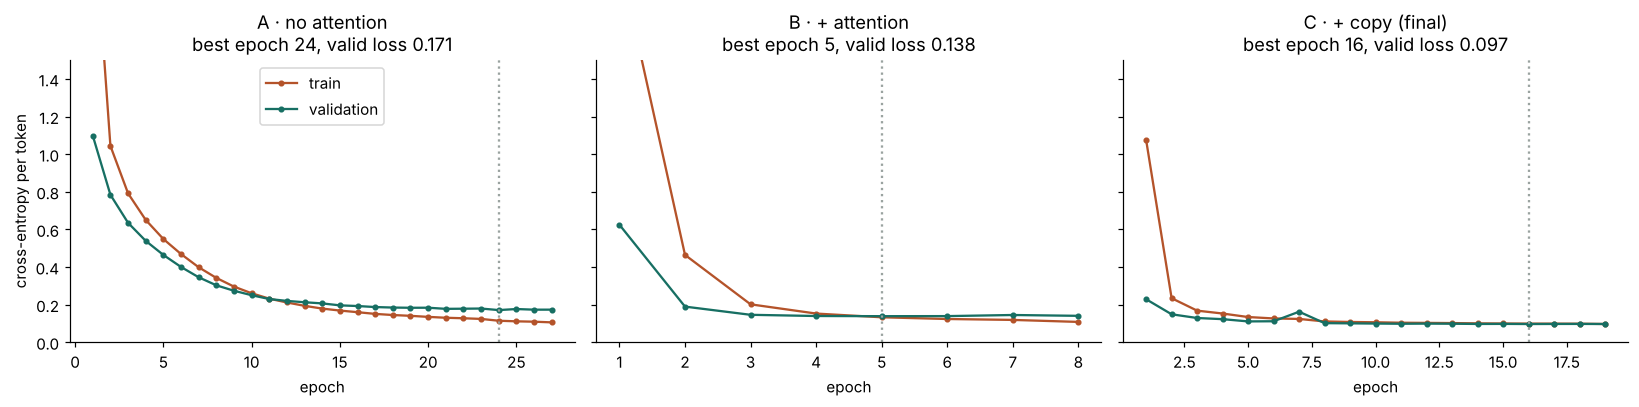

In [22]:
names = {"A_lstm": "A · no attention", "B_attention": "B · + attention", "C_copy_nodrop": "C · + copy (final)"}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, (m, label) in zip(ax, names.items()):
    h = json.loads((EXP / m / "history.json").read_text())
    ep = [e["epoch"] for e in h]
    a.plot(ep, [e["train_loss"] for e in h], "o-", ms=3, color=RUST, label="train")
    a.plot(ep, [e["valid_loss"] for e in h], "o-", ms=3, color=TEAL, label="validation")
    best = min(h, key=lambda e: e["valid_loss"])
    a.axvline(best["epoch"], ls=":", color=GREY)
    a.set_title(f"{label}\nbest epoch {best['epoch']}, valid loss {best['valid_loss']:.3f}")
    a.set_xlabel("epoch")
    a.set_ylim(0, 1.5)
ax[0].set_ylabel("cross-entropy per token")
ax[0].legend()
plt.tight_layout()
plt.show()

In [23]:
# Gap between the training and the validation loss of every model, at its best epoch and at the end
gaps = []
for m in ["A_lstm", "B_attention", "C_copy_nodrop", "C_copy", "D_gru_attention", "E_attention_h128",
          "E_attention_h512", "F_attention_tf0.5"]:
    h = json.loads((EXP / m / "history.json").read_text())
    b = min(h, key=lambda e: e["valid_loss"])
    gaps.append({"model": m, "epochs run": len(h), "best epoch": b["epoch"],
                 "train loss (best)": b["train_loss"], "valid loss (best)": b["valid_loss"],
                 "gap valid − train": b["valid_loss"] - b["train_loss"],
                 "valid loss (last)": h[-1]["valid_loss"]})
pd.DataFrame(gaps).round(3)

,model,epochs run,best epoch,train loss (best),valid loss (best),gap valid − train,valid loss (last)
0,A_lstm,27,24,0.114,0.171,0.057,0.173
1,B_attention,8,5,0.133,0.138,0.006,0.140
2,C_copy_nodrop,19,16,0.099,0.097,-0.002,0.097
3,C_copy,26,26,0.104,0.096,-0.009,0.096
4,D_gru_attention,10,7,0.110,0.137,0.026,0.139
5,E_attention_h128,17,14,0.106,0.130,0.024,0.130
6,E_attention_h512,7,4,0.133,0.137,0.005,0.140
7,F_attention_tf0.5,12,9,0.386,0.175,-0.211,0.181


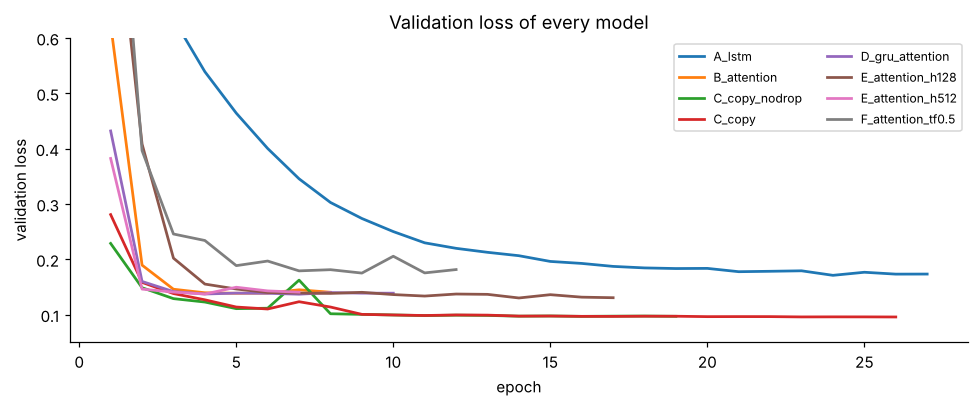

In [24]:
# Validation loss of all the models trained in the project
plt.figure(figsize=(9, 3.8))
for m in pd.DataFrame(gaps).model:
    h = json.loads((EXP / m / "history.json").read_text())
    plt.plot([e["epoch"] for e in h], [e["valid_loss"] for e in h], lw=1.8, label=m)
plt.ylim(0.05, 0.6)
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Validation loss of every model")
plt.legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.show()

- **Slight overfitting without the copy mechanism.** For A, the training loss goes below the
  validation loss from epoch 12 (0.11 vs 0.17 at the best epoch). B, D and E show a smaller gap
  (0.01–0.03) in their last epochs. The validation loss does not really go up, and early stopping
  keeps the best epoch, so the overfitting stays small.
- **No overfitting with the copy mechanism (C, C').** The training and validation losses stay equal
  (≈ 0.10).
- F's training loss is higher than its validation loss. During training, F receives its own
  predictions half of the time, while validation always uses teacher forcing.
- **No underfitting.** The validation losses reach 0.10–0.18 per token. The loss cannot reach 0,
  because each training input has two different references.
- **Attention speeds up learning a lot.** B reaches its best validation loss at epoch 5, A at
  epoch 24, and A stays higher.

## 14. Saving and reloading the model

A checkpoint stores the **configuration** and the **weights** (`state_dict`). To reload a model, I
rebuild it from its configuration and load its weights. First, the model trained just above:

In [25]:
def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model = Seq2Seq(Config.from_dict(ckpt["config"]), len(vocab))
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt


reloaded, _ = load_checkpoint(CKPT_DEMO)
demo_model.eval()
b = next(iter(make_loader(splits["test"].head(8), vocab, 8)))
with torch.no_grad():
    same = torch.allclose(demo_model(b["src"], b["src_len"], b["tgt"], 1.0, b["src_ext"], b["max_oov"]),
                          reloaded(b["src"], b["src_len"], b["tgt"], 1.0, b["src_ext"], b["max_oov"]))
print("the reloaded model gives exactly the same outputs:", same)
CKPT_DEMO.unlink()   # the demo checkpoint is not needed any more

the reloaded model gives exactly the same outputs: True


Now the **fully trained** models A, B and C. By default they are the checkpoints of the project,
trained with the same code, so their weights load into the classes defined in this notebook. With
`FULL_TRAINING = True`, the three models are trained completely here first (early stopping, about
1 hour on a CPU). The training is deterministic, so the results are the same.

In [26]:
FULL_TRAINING = False

models = {}
rows = []
for m in ["A_lstm", "B_attention", "C_copy_nodrop"]:
    path = CKPT / f"{m}.pt"
    if FULL_TRAINING:
        path = CKPT / f"notebook_{m}.pt"
        print(f"--- training {m}")
        train_model(configs[m], train_df, splits["valid"], epochs=configs[m].epochs, save_path=path)
    models[m], ckpt = load_checkpoint(path)
    rows.append({"model": names[m], "checkpoint": path.name, "parameters": f"{count_parameters(models[m]):,}",
                 "best epoch": ckpt["epoch"], "validation loss": round(ckpt["valid_loss"], 4)})
pd.DataFrame(rows)

,model,checkpoint,parameters,best epoch,validation loss
0,A · no attention,A_lstm.pt,"1,303,693",24,0.1709
1,B · + attention,B_attention.pt,"1,664,397",5,0.1385
2,C · + copy (final),C_copy_nodrop.pt,"1,665,038",16,0.0967


## 15. Generation on new inputs

At inference time there is no reference: the decoder starts with `<SOS>`, and each predicted word
becomes the input of the next step, until `<EOS>`. I implemented three decoding strategies:

- **greedy** (required): at each step, take the most probable word;
- **beam search** (k = 5): keep the 5 best partial sentences at each step. Finished sentences are
  compared with a length-normalised score $\log P(y) / |y|$, otherwise short outputs would always
  win;
- **sampling** with temperature, top-k or top-p: draw the next word at random, which gives more
  varied but riskier outputs.

In [27]:
def encode_inputs(model, token_lists):
    b = collate([encode_example(t, None, vocab) for t in token_lists])
    enc_out, state, mask, keys = model.encode(b["src"], b["src_len"])
    return b, b["src_ext"], (b["max_oov"] if model.cfg.copy else 0), enc_out, state, mask, keys


@torch.no_grad()
def greedy_decode(model, token_lists, max_len=40, sample=None):
    """Greedy decoding of a batch. sample = {"temperature", "top_k", "top_p", "seed"} for sampling."""
    b, src_ext, max_oov, enc_out, state, mask, keys = encode_inputs(model, token_lists)
    gen = torch.Generator().manual_seed(sample.get("seed", 0)) if sample else None
    inp = torch.full((len(token_lists),), SOS)
    ids, attns, done = [], [], torch.zeros(len(token_lists), dtype=torch.bool)
    for _ in range(max_len):
        log_probs, state, w, _ = model.decoder.step(inp, state, enc_out, keys, mask, src_ext, max_oov)
        if sample:
            logits = log_probs / sample.get("temperature", 1.0)
            if sample.get("top_k"):
                kth = logits.topk(sample["top_k"], dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            if sample.get("top_p"):
                sorted_l, order = logits.sort(dim=-1, descending=True)
                p = sorted_l.softmax(-1)
                logits = logits.scatter(1, order, sorted_l.masked_fill(p.cumsum(-1) - p > sample["top_p"], float("-inf")))
            nxt = torch.multinomial(logits.softmax(-1), 1, generator=gen).squeeze(1)
        else:
            nxt = log_probs.argmax(-1)                # the most probable word
        ids.append(nxt)
        attns.append(w)
        done |= nxt == EOS
        if done.all():
            break
        inp = model.to_input(nxt)                     # the prediction is the next input
    ids = torch.stack(ids, 1).tolist()
    results = []
    for i, seq in enumerate(ids):
        n = seq.index(EOS) + 1 if EOS in seq else len(seq)
        att = None if attns[0] is None else torch.stack([a[i, :int(b["src_len"][i])] for a in attns[:n]]).numpy()
        results.append({"tokens": vocab.decode(seq[:n], b["oovs"][i]), "attention": att})
    return results


@torch.no_grad()
def beam_search(model, tokens, k=5, max_len=40, alpha=1.0):
    """Beam search for one sentence (the k hypotheses are decoded as a batch)."""
    b, src_ext, max_oov, enc_out, state, mask, keys = encode_inputs(model, [tokens])
    beams, finished = [(0.0, [SOS])], []
    for _ in range(max_len):
        n = len(beams)
        expand = lambda x: None if x is None else x.expand(n, *x.shape[1:])
        inp = model.to_input(torch.tensor([seq[-1] for _, seq in beams]))
        log_probs, new_state, _, _ = model.decoder.step(inp, state, expand(enc_out), expand(keys), expand(mask),
                                                        expand(src_ext), max_oov)
        top_lp, top_id = log_probs.topk(k, dim=-1)
        candidates = sorted(((score + lp, seq + [wid], i) for i, (score, seq) in enumerate(beams)
                             for lp, wid in zip(top_lp[i].tolist(), top_id[i].tolist())), key=lambda c: c[0], reverse=True)
        beams, keep = [], []
        for score, seq, i in candidates:
            if seq[-1] == EOS:
                finished.append((score / (len(seq) - 1) ** alpha, seq))      # length-normalised score
            else:
                beams.append((score, seq))
                keep.append(i)
            if len(beams) == k:
                break
        if len(finished) >= k or not beams:
            break
        keep = torch.tensor(keep)
        state = tuple(s[:, keep] for s in new_state) if isinstance(new_state, tuple) else new_state[:, keep]
    if not finished:
        finished = [(s / (len(q) - 1) ** alpha, q) for s, q in beams]
    return vocab.decode(max(finished, key=lambda f: f[0])[1][1:], b["oovs"][0])


def restore_case(tokens, source_text):
    """For display: give output words the case they had in the input (sarah -> Sarah)."""
    cased, prev = {}, "."
    for t in TOKEN_RE.findall(unicodedata.normalize("NFKC", source_text).translate(QUOTES)):
        if t.lower() != t and (len(t) > 1 and t[1:].lower() != t[1:] or prev not in ".!?:"):
            cased.setdefault(t.lower(), t)
        prev = t
    return [cased.get(t, t) for t in tokens]


def rewrite(text, model, strategy="beam", **kw):
    toks = tokenize(text)
    if strategy == "beam":
        out = beam_search(model, toks)
    elif strategy == "sample":
        out = greedy_decode(model, [toks], sample=kw)[0]["tokens"]
    else:
        out = greedy_decode(model, [toks])[0]["tokens"]
    return detokenize(restore_case(out, text), capitalize=True)

New sentences written for this notebook. None of them is in the dataset:

In [28]:
new_sentences = ["Close the window now.",
                 "Stop interrupting me during meetings.",
                 "You're wrong, the meeting is on Tuesday.",
                 "Give me my keys back, I need them right now.",
                 "Why is the printer still broken?",
                 "I won't help you move this weekend."]
all_inputs = set(pd.concat([df.impolite for df in splits.values()]))
assert not any(s in all_inputs for s in new_sentences)

C = models["C_copy_nodrop"]
pd.DataFrame([{"input": s, "greedy": rewrite(s, C, "greedy"), "beam search (5)": rewrite(s, C, "beam")} for s in new_sentences])

,input,greedy,beam search (5)
0,Close the window now.,Would you mind closing the window as soon as possible?,Would you mind closing the window as soon as possible?
1,Stop interrupting me during meetings.,"Would you mind not interrupting me during meetings, please?","Would you mind not interrupting me during meetings, please?"
2,"You're wrong, the meeting is on Tuesday.","I might be mistaken, but I believe the meeting is on Tuesday.","I might be mistaken, but I believe the meeting is on Tuesday."
3,"Give me my keys back, I need them right now.",Could you please give me my keys back? Need need them.,Could you please give me my keys back?
4,Why is the printer still broken?,"Could you tell me why the printer is still broken, please?",I was wondering if you could tell me why the printer is still broken.
5,I won't help you move this weekend.,Could you please help you move this weekend?,I would really appreciate it if you could help you move this weekend.


The model rewrites most new sentences well, but two outputs show typical errors:
- with greedy decoding, *"Give me my keys back, I need them right now"* ends with a repeated word
  (*"Need need them."*). Beam search avoids it, but it drops the explanation;
- *"I won't help you move this weekend"* is a **refusal**, but the model turns it into a request
  (*"…could you help you move…"*). The meaning is lost. This kind of error is analysed in section 19.

In [29]:
# Sampling: the same input, 4 random draws (seeds 0-3) for each sampling strategy
s = "Turn the music down, it's too loud."
strategies = {"temperature 0.7": {"temperature": 0.7}, "temperature 1.3": {"temperature": 1.3},
              "top-k 5": {"temperature": 1.0, "top_k": 5}, "top-p 0.9": {"top_p": 0.9}}
pd.DataFrame({name: [rewrite(s, C, "sample", seed=seed, **kw) for seed in range(4)] for name, kw in strategies.items()},
             index=[f"seed {seed}" for seed in range(4)])

,temperature 0.7,temperature 1.3,top-k 5,top-p 0.9
seed 0,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.
seed 1,Could you please turn the music down? Too loud loud.,I would really appreciate it if you could turn the music down. Too loud.,Could I ask you to turn the music down? Thank you! Too loud.,Could I ask you to turn the music down? Thank you! Too loud.
seed 2,Would you mind turning the music down? Too loud.,Would you mind turning the music down?,Would you mind turning the music down?,Would you mind turning the music down?
seed 3,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.,Could I ask you to turn the music down? Thank you! Loud loud.


Sampling gives different outputs for different seeds, and a higher temperature (1.3) gives more
variety (*"I would really appreciate it if you could…"*). With the same seed, the strategies often
choose the same words, because the model is very confident: most words get a probability above 0.97.
This example is also difficult for the model. The second idea, *"it's too loud"*, is often lost or
garbled (*"Loud loud."*).

## 16. Examples: input, expected output, generated output

Final model (C, beam search with 5 beams) on the three test sets. "Expected" is one of the polite
references of the dataset. The model does not need to produce exactly this sentence: any polite
sentence with the same content is fine.

In [30]:
def multiref(split):
    df = splits[split]
    return [{"impolite": imp, "category": cat, "references": list(g.polite)}
            for (imp, cat), g in df.groupby(["impolite", "category"], sort=False)]


examples = []
for split in ["test", "test_unseen", "challenge"]:
    for ex in pd.DataFrame(multiref(split)).sample(3, random_state=1).to_dict("records"):
        examples.append({"set": split, "input": ex["impolite"], "expected": ex["references"][0],
                         "generated": detokenize(beam_search(C, tokenize(ex["impolite"])), capitalize=True)})
pd.DataFrame(examples)

,set,input,expected,generated
0,test,What kind of service is this? My order has been delayed for two hours.,"Hi, I'm writing because my order has been delayed for two hours. I would appreciate your help.","I'm sorry to bother you, but my order has been delayed for two hours. Could you help me?"
1,test,I want answers now. My flight booking number 8183 was cancelled without notice again.,"Excuse me, it seems that my flight booking number 8183 was cancelled without notice again. Would you be ab...","I'm sorry to bother you, but my flight booking number 8183 was cancelled without notice again. Could you h..."
2,test,What is this timeline for Saturday? It's so confusing.,I noticed the timeline for Saturday is a bit confusing. Could we work on that together?,"I appreciate the effort on the timeline for saturday, but it is a bit confusing."
3,test_unseen,The cooking class will be led by Maya. Take it or leave it.,I wanted to let you know that the cooking class will be led by Maya.,I'm sorry to say that the cooking class will be led by maya. Thanks for your patience.
4,test_unseen,"Like I said, the book club is cancelled. Move on.",I wanted to let you know that the book club is cancelled.,I'm sorry to say that the book club is cancelled. Thanks for your patience.
5,test_unseen,"Nobody cares, the hiking trip is cancelled because of the weather.","For your information, the hiking trip is cancelled because of the weather. Please let me know if you have ...",I wanted to let you know that the hiking trip is cancelled because of the weather.
6,challenge,No. I won't proofread your thesis.,"I'm sorry, but I can't proofread your thesis.","I'm sorry, but I won't be able to proofread your thesis."
7,challenge,Is the report done or what?,Could you let me know if the report is done?,Could you please let me know whether the report is done?
8,challenge,I still don't have your signature on the form.,Could you please sign the form when you have a moment?,I wanted to follow up: could you your signature on the form?


**The examples of the report.** Here are the four examples used in the report (hand-written challenge
set), with the output of the final model, the automatic metric and the human judgement:

In [31]:
human_labels = pd.read_csv(REPORTS / "human_eval_challenge_C_copy_nodrop__beam5.csv", keep_default_na=False)
report_examples = ["Turn the music down.", "You're wrong. Water boils at 100 degrees.",
                   "I won't lend you any more money.", "You were supposed to pay the rent yesterday."]
rows = []
for s in report_examples:
    label = human_labels[human_labels.impolite == s].iloc[0]
    rows.append({"input": s, "generated (C, beam 5)": detokenize(beam_search(C, tokenize(s)), capitalize=True),
                 "automatic success": bool(label.automatic_success), "human judgement": label.human_label})
pd.DataFrame(rows)

,input,"generated (C, beam 5)",automatic success,human judgement
0,Turn the music down.,Could I ask you to turn the music down? Thank you!,True,acceptable
1,You're wrong. Water boils at 100 degrees.,"Actually, I think water boils at 100 degrees. Could you double-check?",True,acceptable
2,I won't lend you any more money.,Would it be possible for you to lend you any more money?,True,failed
3,You were supposed to pay the rent yesterday.,"Whenever you get a chance, could you pay the rent yesterday?",True,partial


The last two outputs are polite and keep all the content words, so the **automatic metric counts
them as successes**. But a human sees that the meaning is reversed (a refusal became a request) and
that the tense is wrong. This is why the evaluation also includes a human judgement (section 19.4).

## 17. Evaluation

### 17.1 Metrics

One metric is not enough for this task, so I use several:

| Metric | What it measures | Why |
|---|---|---|
| **BLEU** (1–4-grams, several references) | n-gram overlap with the references | standard for generation; implemented by hand and checked against `sacrebleu` |
| **chrF** | character n-gram F-score | more tolerant to small changes (*close / closing*) |
| **Exact match** | output = one of the references | strict |
| **Content kept** | % of the content words of the input (action, object, person, time…) still in the output | faithfulness: BLEU does not check this |
| **Politeness** | P(polite) given by a politeness classifier | the tone: the references do not cover every polite phrasing |
| **Success** | polite (≥ 0.5) **and** all content kept **and** no repeated word | one usable rewrite = main score |
| Token accuracy, perplexity | with teacher forcing | diagnostics of the language model |

The **politeness classifier** is a logistic regression on words and pairs of words, written with
numpy. It is trained on the training set only: impolite sentences = 0, polite references = 1.

In [32]:
class PolitenessClassifier:
    @staticmethod
    def features(tokens):     # words + pairs of words (with sentence boundaries)
        t = ["<s>"] + tokens + ["</s>"]
        return set(tokens) | {a + " " + b for a, b in zip(t, t[1:])}

    def matrix(self, sentences):
        X = np.zeros((len(sentences), len(self.vocab)), dtype=np.float32)
        for i, s in enumerate(sentences):
            for f in self.features(tokenize(s) if isinstance(s, str) else s):
                if f in self.vocab:
                    X[i, self.vocab[f]] = 1.0
        return X

    def fit(self, sentences, labels, min_count=3, l2=1e-3, lr=0.5, epochs=300):
        counts = Counter(f for s in sentences for f in self.features(tokenize(s)))
        self.vocab = {f: i for i, f in enumerate(sorted(f for f, c in counts.items() if c >= min_count))}
        X, y = self.matrix(sentences), np.asarray(labels, dtype=np.float32)
        self.w, self.b = np.zeros(X.shape[1], dtype=np.float32), 0.0
        for _ in range(epochs):                       # gradient descent on the log-loss
            p = 1 / (1 + np.exp(-(X @ self.w + self.b)))
            self.w -= lr * (X.T @ (p - y) / len(y) + l2 * self.w)
            self.b -= lr * (p - y).mean()
        return self

    def predict_proba(self, sentences):
        return 1 / (1 + np.exp(-(self.matrix(sentences) @ self.w + self.b)))


t0 = time.time()
sents = list(train_df.impolite.drop_duplicates()) + list(train_df.polite.drop_duplicates())
labels = [0] * train_df.impolite.nunique() + [1] * train_df.polite.nunique()
clf = PolitenessClassifier().fit(sents, labels)
print(f"trained in {time.time() - t0:.0f} s on {len(sents):,} sentences, {len(clf.vocab):,} features")
for s in ["test_unseen", "challenge"]:
    df = splits[s]
    print(f"{s:12} impolite recognised {np.mean(clf.predict_proba(list(df.impolite.unique())) < .5):.3f} | "
          f"polite recognised {np.mean(clf.predict_proba(list(df.polite.unique())) >= .5):.3f}")
order = np.argsort(clf.w)
inv = {i: f for f, i in clf.vocab.items()}
print("most polite features:  ", [inv[i] for i in order[::-1][:8]])
print("most impolite features:", [inv[i] for i in order[:8]])

trained in 98 s on 43,200 sentences, 12,680 features
test_unseen  impolite recognised 0.966 | polite recognised 1.000
challenge    impolite recognised 1.000 | polite recognised 0.778
most polite features:   ['could', 'i', 'a', 'but', ', but', 'would', 'could you', 'if']
most impolite features: ['. </s>', '.', 'not', 'no', 'stop', "it's", 'twice', 'the']


In [33]:
PUNCT = set(".,!?;:'\"()-")
STOP = set("""a an the to of in on at for from with by and or but so if it its it's is are was were be been
being am i you he she we they me my your our their this that these those do does did have has had will
would could can may might should please thank thanks sorry just again now still yet not no don't won't
can't i'm i'd you're there what when where who why how which as up out about into then than too very
really already""".split())     # function words and politeness words: not "content"


def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def corpus_bleu(hyps, refs, max_n=4):
    match, total, hyp_len, ref_len = [0] * max_n, [0] * max_n, 0, 0
    for hyp, rs in zip(hyps, refs):
        hyp_len += len(hyp)
        ref_len += min((abs(len(x) - len(hyp)), len(x)) for x in rs)[1]       # closest reference length
        for n in range(1, max_n + 1):
            best = Counter()
            for x in rs:
                best |= ngrams(x, n)
            match[n - 1] += sum(min(v, best[g]) for g, v in ngrams(hyp, n).items())   # clipped counts
            total[n - 1] += max(len(hyp) - n + 1, 0)
    if hyp_len == 0 or min(match) == 0:
        return 0.0
    log_p = sum(math.log(m / t) for m, t in zip(match, total)) / max_n         # geometric mean of precisions
    bp = 1.0 if hyp_len > ref_len else math.exp(1 - ref_len / hyp_len)           # brevity penalty
    return 100 * bp * math.exp(log_p)


def stem(w):        # small stemmer: "closing" and "close" count as the same word
    w = w.lower()
    if w.endswith("'s"):
        w = w[:-2]
    for suf in ("ing", "ed", "es", "s"):
        if w.endswith(suf) and len(w) - len(suf) >= 3:
            w = w[:-len(suf)]
            break
    if len(w) >= 4 and w[-1] == w[-2] and w[-1] not in "lsz":
        w = w[:-1]
    return w.rstrip("e") or w


def content_words(src, refs):    # words of the input that all references keep
    common = {stem(w) for w in src if w not in STOP and w not in PUNCT}
    for r in refs:
        common &= {stem(w) for w in r}
    return common


def has_repetition(tokens):
    return any(a == b and a not in PUNCT for a, b in zip(tokens, tokens[1:]))


def evaluate_outputs(data, outputs):
    srcs = [tokenize(ex["impolite"]) for ex in data]
    refs = [[tokenize(r) for r in ex["references"]] for ex in data]
    polite = clf.predict_proba(outputs)
    rows = []
    for src, out, rs, p in zip(srcs, outputs, refs, polite):
        keep = content_words(src, rs)
        content = len(keep & {stem(w) for w in out}) / len(keep) if keep else 1.0
        rep = has_repetition(out)
        rows.append({"exact": any(out == r for r in rs), "content": content, "polite": p >= 0.5, "repetition": rep,
                     "chrf": sacrebleu.sentence_chrf(detokenize(out), [detokenize(r) for r in rs]).score,
                     "success": p >= 0.5 and content == 1.0 and not rep and len(out) > 0})
    r = pd.DataFrame(rows)
    metrics = {"BLEU": corpus_bleu(outputs, refs), "chrF": r.chrf.mean(), "exact match": r.exact.mean(),
               "content kept": r.content.mean(), "polite": r.polite.mean(), "repetitions": r.repetition.mean(),
               "success": r.success.mean()}
    return metrics, r


# check of my BLEU against sacrebleu on a small example
h = [["could", "you", "send", "me", "the", "report", "?"]]
rf = [[["could", "you", "send", "me", "the", "report", "today", "?"], ["please", "send", "the", "report", "."]]]
print(f"my BLEU {corpus_bleu(h, rf):.4f} | sacrebleu {sacrebleu.corpus_bleu([' '.join(h[0])], [[' '.join(rf[0][0])], [' '.join(rf[0][1])]], tokenize='none').score:.4f}")

my BLEU 72.8955 | sacrebleu 72.8955


### 17.2 Baselines

Two systems without machine learning:
- **copy**: the output is the input. It keeps all the content but stays impolite;
- **rules**: remove the usual rude words (*now*, *seriously*, *hurry up*…) and add *please* at the
  beginning.

In [34]:
RUDE_MARKERS = [
    "and stop wasting my time", "i am not asking twice", "i'm not asking twice", "no excuses",
    "deal with it", "not my problem", "stop asking me about it", "stop asking", "get it right",
    "i don't have all day", "answer me", "hurry up", "end of discussion", "get used to it",
    "this is ridiculous", "unbelievable", "for the last time", "how many times do i have to ask",
    "are you even listening", "it's annoying", "understood", "already", "right now", "immediately",
    "now", "seriously", "honestly", "obviously", "come on", "just", "look", "listen", "well",
    "whatever", "period", "do it", "no way", "forget it", "absolutely not", "typical", "again",
]
RUDE_RE = re.compile(r"\b(" + "|".join(re.escape(m) for m in sorted(RUDE_MARKERS, key=len, reverse=True)) + r")\b")


def rules_baseline(tokens):
    out = tokenize(RUDE_RE.sub(" ", detokenize(tokens)))
    cleaned = []
    for t in out:                       # remove punctuation left alone after the deletions
        if t in ",.!?" and (not cleaned or cleaned[-1] in ",.!?"):
            continue
        cleaned.append(t)
    return ["please", ","] + cleaned if cleaned else ["please", "."]


print(detokenize(rules_baseline(tokenize("Send me the report right now, seriously.")), capitalize=True))

Please, send me the report,


### 17.3 Results on the three test sets

All the systems are evaluated on the same inputs. The models use greedy decoding, and the final
system uses beam search (5). The decoding strategy was chosen on the validation set (section 18).

In [35]:
test_sets = {s: multiref(s) for s in ["test", "test_unseen", "challenge"]}
systems = {
    "copy baseline": lambda toks: toks,
    "rules baseline": lambda toks: [rules_baseline(t) for t in toks],
    "A · no attention": lambda toks: [r["tokens"] for r in greedy_decode(models["A_lstm"], toks)],
    "B · + attention": lambda toks: [r["tokens"] for r in greedy_decode(models["B_attention"], toks)],
    "C · + copy": lambda toks: [r["tokens"] for r in greedy_decode(C, toks)],
    "C · + copy, beam 5 (final)": lambda toks: [beam_search(C, t) for t in toks],
}
results, details = [], {}
t0 = time.time()
for split, data in test_sets.items():
    toks = [tokenize(ex["impolite"]) for ex in data]
    for name, system in systems.items():
        outputs = system(toks)
        metrics, details[(name, split)] = evaluate_outputs(data, outputs)
        details[(name, split)]["output"] = outputs
        results.append({"system": name, "split": split, **metrics})
results = pd.DataFrame(results)
print(f"evaluation done in {time.time() - t0:.0f} s")
success = results.pivot(index="system", columns="split", values="success").loc[list(systems)][["test", "test_unseen", "challenge"]]
success.round(3)

evaluation done in 59 s


split,test,test_unseen,challenge
system,,,
copy baseline,0.000,0.034,0.000
rules baseline,0.125,0.253,0.097
A · no attention,0.845,0.350,0.111
B · + attention,0.912,0.582,0.222
C · + copy,0.998,0.758,0.764
"C · + copy, beam 5 (final)",0.999,0.787,0.764


In [36]:
# All metrics on the hand-written challenge set
results[results.split == "challenge"].set_index("system").drop(columns="split").round(3)

,BLEU,chrF,exact match,content kept,polite,repetitions,success
system,,,,,,,
copy baseline,28.061,48.071,0.000,1.000,0.000,0.000,0.000
rules baseline,29.986,49.588,0.000,1.000,0.097,0.000,0.097
A · no attention,13.289,32.785,0.000,0.343,1.000,0.000,0.111
B · + attention,18.411,40.552,0.000,0.506,1.000,0.056,0.222
C · + copy,30.541,54.033,0.014,0.923,1.000,0.056,0.764
"C · + copy, beam 5 (final)",27.429,51.779,0.000,0.926,1.000,0.056,0.764


In [37]:
# Consistency check with the numbers of the project (reports/results.json, made by evaluate.py)
project = {(r["system"], r["split"]): r["success_rate"] for r in json.loads((REPORTS / "results.json").read_text())}
ids = {"copy baseline": "baseline_copy", "rules baseline": "baseline_rules", "A · no attention": "A_lstm",
       "B · + attention": "B_attention", "C · + copy": "C_copy_nodrop", "C · + copy, beam 5 (final)": "C_copy_nodrop__beam5"}
diff = max(abs(success.loc[n, s] - project[(ids[n], s)]) for n in ids for s in success.columns)
print("largest difference with reports/results.json:", round(diff, 6))

largest difference with reports/results.json: 0.0


In [38]:
# Token accuracy and perplexity of the three models on the test set (teacher forcing)
test_loader = make_loader(splits["test"], vocab, 64)
pd.DataFrame([{"model": names[m], "token accuracy": run_epoch(models[m], test_loader, 1.0)[1],
               "perplexity": math.exp(run_epoch(models[m], test_loader, 1.0)[0])} for m in models]).round(3)

,model,token accuracy,perplexity
0,A · no attention,0.947,1.192
1,B · + attention,0.949,1.152
2,C · + copy (final),0.955,1.102


## 18. Baseline vs improvements

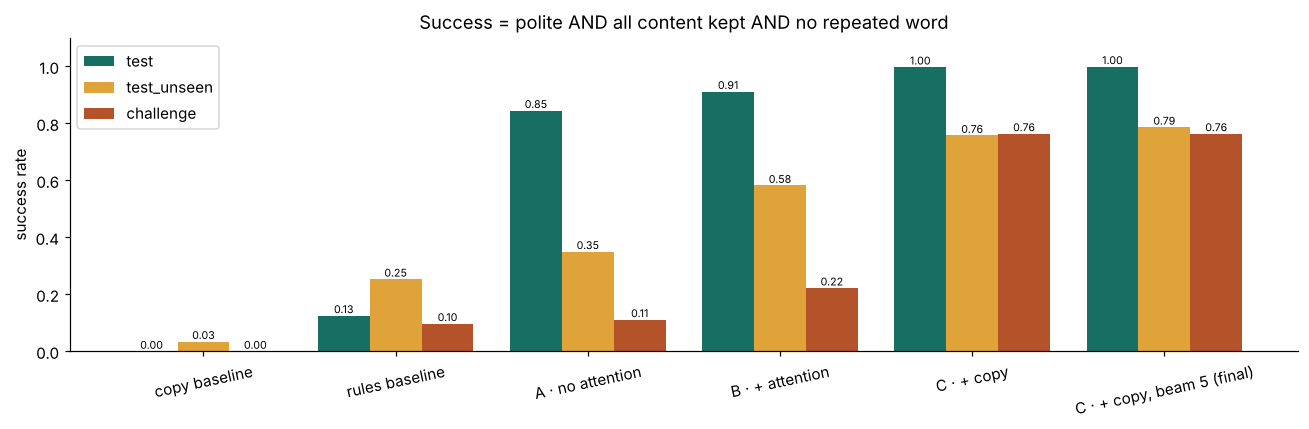

In [39]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(success))
for i, (split, color) in enumerate(zip(success.columns, [TEAL, ORANGE, RUST])):
    bars = ax.bar(x + (i - 1) * 0.27, success[split], 0.27, label=split, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(x, success.index, rotation=12)
ax.set_ylabel("success rate")
ax.set_ylim(0, 1.1)
ax.set_title("Success = polite AND all content kept AND no repeated word")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **The baselines fail.** Copying keeps the content but is never polite. The rules make only about
  10 % of the hand-written sentences successful, so the task needs more than deleting words.
- **A (no attention)** learns the task on familiar phrasings (0.85 on test) but collapses on new
  phrasings (0.35) and hand-written sentences (0.11). The single vector loses the content.
- **Attention (B)** improves every test set, especially test_unseen (0.58). In the curves, it also
  reaches its best loss much faster.
- **The copy mechanism (C) gives the biggest gain**: hand-written sentences go from 0.22 to 0.76. Most
  errors of B were content words (objects, names) replaced by frequent training words.
- **Beam search** adds a little on top of greedy decoding.

- **BLEU and success do not always agree.** With greedy decoding, C has a slightly higher BLEU on
  test (78.6) than with beam search (77.2), but a lower success on test_unseen (0.758 vs 0.787).
  BLEU rewards closeness to the reference phrasings, while success checks politeness and content. The
  final system was chosen on the success rate on validation (below).

### 18.1 All the models trained in the project

The table compares all the models: the three models above and the variants (GRU, hidden size,
teacher forcing, word dropout). The variants were trained with the same code (`train.py`), and their
numbers are read from the project files (`experiments/`, `reports/results.json`), because training
them again here would take hours.

In [40]:
all_results = json.loads((REPORTS / "results.json").read_text())
res = {(r["system"], r["split"]): r for r in all_results}
labels = {"A_lstm": "A · LSTM, no attention (baseline)", "B_attention": "B · + attention",
          "C_copy_nodrop": "C · + copy", "C_copy_nodrop__beam5": "C · + copy, beam 5 (final)",
          "C_copy": "C' · copy + word dropout", "D_gru_attention": "D · B with GRU cells",
          "E_attention_h128": "E · B with hidden size 128", "E_attention_h512": "E · B with hidden size 512",
          "F_attention_tf0.5": "F · B with teacher forcing 0.5"}
rows = []
for system, label in labels.items():
    m = system.split("__")[0]
    summary = json.loads((EXP / m / "train_summary.json").read_text())
    rows.append({"model": label, "parameters": f"{summary['params'] / 1e6:.2f} M", "epochs run": summary["epochs_run"],
                 "best epoch": summary["best_epoch"], "valid loss": round(summary["best_valid_loss"], 3),
                 "BLEU test": round(res[(system, "test")]["BLEU"], 1),
                 **{f"success {s}": round(res[(system, s)]["success_rate"], 3) for s in ("test", "test_unseen", "challenge")}})
pd.DataFrame(rows)

,model,parameters,epochs run,best epoch,valid loss,BLEU test,success test,success test_unseen,success challenge
0,"A · LSTM, no attention (baseline)",1.30 M,27,24,0.171,74.2,0.845,0.350,0.111
1,B · + attention,1.66 M,8,5,0.138,77.2,0.912,0.582,0.222
2,C · + copy,1.67 M,19,16,0.097,78.6,0.998,0.758,0.764
3,"C · + copy, beam 5 (final)",1.67 M,19,16,0.097,77.2,0.999,0.787,0.764
4,C' · copy + word dropout,1.67 M,26,26,0.096,78.2,0.998,0.682,0.681
5,D · B with GRU cells,1.40 M,10,7,0.137,77.3,0.928,0.578,0.236
6,E · B with hidden size 128,0.88 M,17,14,0.130,77.1,0.928,0.630,0.236
7,E · B with hidden size 512,4.42 M,7,4,0.137,77.2,0.921,0.613,0.236
8,F · B with teacher forcing 0.5,1.66 M,12,9,0.175,77.2,0.921,0.572,0.250


- A **bigger model** (hidden 512), a **smaller one** (128), **GRU cells** or **teacher forcing 0.5**
  give no real gain (0.92–0.93 on test, against 0.91 for B). A larger model does not help: the limit is the data
  and the architecture, not the size.
- **Word dropout** (C') was meant to help with unknown words, but it made the results worse.

### 18.2 Effect of the dataset (version 1 → version 2)

The hand-written challenge set is the same for both versions of the dataset. I kept the outputs of the
first models A and B trained on version 1 (`archive_v1/`), so they can be scored again here with
exactly the same metric:

In [41]:
challenge = test_sets["challenge"]
names_eval = {"A_lstm": "A · no attention", "B_attention": "B · + attention"}   # names used in section 17.3
v1_rows = []
for m in ["A_lstm", "B_attention"]:
    old = pd.read_csv(ROOT / "archive_v1" / m / "challenge_predictions.csv", keep_default_na=False)
    assert list(old.impolite) == [ex["impolite"] for ex in challenge]
    metrics_v1, _ = evaluate_outputs(challenge, [tokenize(x) for x in old.prediction])
    metrics_v2 = results[(results.system == names_eval[m]) & (results.split == "challenge")].iloc[0]
    v1_rows.append({"model": names[m], "success (v1 data)": metrics_v1["success"], "success (v2 data)": metrics_v2["success"],
                    "content kept (v1 data)": metrics_v1["content kept"], "content kept (v2 data)": metrics_v2["content kept"]})
pd.DataFrame(v1_rows).round(3)

,model,success (v1 data),success (v2 data),content kept (v1 data),content kept (v2 data)
0,A · no attention,0.014,0.111,0.090,0.343
1,B · + attention,0.000,0.222,0.191,0.506


With the first version of the data, the models almost never succeeded on hand-written sentences
(0–1 %) and kept only 9–19 % of their content words. The same architectures trained on version 2
reach 11 % and 22 %. Improving the data mattered as much as the architecture.

### 18.3 Decoding strategies (validation set)

The decoding strategy is chosen on the **validation** set and compared with greedy decoding. All the
strategies are computed here with model C. Top-p is the only one that was not in the project
evaluation.

In [42]:
def evaluate_decoding(strategy):
    data = multiref("valid")
    toks = [tokenize(ex["impolite"]) for ex in data]
    if strategy.startswith("beam"):
        outputs = [beam_search(C, t, k=int(strategy[4:])) for t in toks]
    else:
        sample = {"greedy": None, "sample_t0.7": {"temperature": 0.7, "seed": 0},
                  "topk5": {"temperature": 1.0, "top_k": 5, "seed": 0}, "topp0.9": {"top_p": 0.9, "seed": 0}}[strategy]
        outputs = []
        for i in range(0, len(toks), 256):     # batches of 256, as in evaluate.py
            outputs += [r["tokens"] for r in greedy_decode(C, toks[i:i + 256], sample=sample)]
    return evaluate_outputs(data, outputs)[0]


t0 = time.time()
decoding = pd.DataFrame([{"decoding": d, **evaluate_decoding(d)}
                         for d in ["greedy", "beam3", "beam5", "sample_t0.7", "topk5", "topp0.9"]]).set_index("decoding")
print(f"computed in {time.time() - t0:.0f} s")
known = {d: res[("C_copy_nodrop" + ("" if d == "greedy" else "__" + d), "valid")]["success_rate"]
         for d in ["greedy", "beam3", "beam5", "sample_t0.7", "topk5"]}
print("largest difference with reports/results.json:", round(max(abs(decoding.loc[d, "success"] - v) for d, v in known.items()), 6))
decoding.round(3)

computed in 67 s
largest difference with reports/results.json: 0.0


,BLEU,chrF,exact match,content kept,polite,repetitions,success
decoding,,,,,,,
greedy,78.464,83.768,0.512,0.999,1.0,0.0,0.998
beam3,78.154,83.793,0.518,1.000,1.0,0.0,0.999
beam5,78.529,84.152,0.527,1.000,1.0,0.0,1.000
sample_t0.7,79.335,83.956,0.522,1.000,1.0,0.0,0.999
topk5,78.618,83.562,0.511,0.999,1.0,0.0,0.998
topp0.9,78.908,83.685,0.516,1.000,1.0,0.0,0.999


- On validation, all the strategies are **very close** (success between 0.99 and 1.00), because these
  sentences use phrasings seen in training. **Beam search (5)** is the only one that reaches 1.000, so
  the final system is **C + beam search 5**. Beam search compares whole sentences, which avoids a few
  repetitions and lost words of greedy decoding.
- **Sampling** (temperature, top-k, top-p) is not worse here, but it is random: the same input gives
  different outputs (section 15). This is nice for variety, but it is less reliable for a tool that
  must keep the meaning. On new sentences, greedy decoding can also repeat a word (*"Need need them"*
  in section 15), which beam search avoided.

## 19. Analysis of results, errors and limits

### 19.1 Which inputs are difficult?

In [43]:
by_cat = []
for split in ["test_unseen", "challenge"]:
    d = details[("C · + copy, beam 5 (final)", split)].copy()
    d["category"] = [ex["category"] for ex in test_sets[split]]
    by_cat.append(d.groupby("category").success.mean().rename(split))
pd.concat(by_cat, axis=1).round(2).sort_values("challenge")

,test_unseen,challenge
category,,
refusal,0.69,0.50
announcement,1.00,0.62
disagreement,0.61,0.62
complaint,0.67,0.62
criticism,0.85,0.75
reminder,0.91,0.88
stop,0.88,0.88
question,0.83,1.00
request,0.64,1.00


### 19.2 Failure cases

In [44]:
d = details[("C · + copy, beam 5 (final)", "challenge")]
fails = []
for ex, (_, r) in zip(test_sets["challenge"], d.iterrows()):
    if not r.success:
        reason = "content lost" if r.content < 1 else ("not polite" if not r.polite else "repetition")
        fails.append({"input": ex["impolite"], "generated": detokenize(r.output, capitalize=True), "automatic reason": reason})
print(f"{len(fails)} failures out of {len(d)} hand-written sentences")
pd.DataFrame(fails).head(10)

17 failures out of 72 hand-written sentences


,input,generated,automatic reason
0,The library books are overdue. Return them.,I wanted to let you know that the library books are overdue.,content lost
1,I'm not babysitting your kids this weekend.,"I'm sorry, but I won't be able to check kids this weekend.",content lost
2,Don't count on me for the camping trip.,I wanted to follow up: could you me me for the camping trip?,repetition
3,Not interested in your offer.,"I'm sorry, but I won't be able to in your offer.",content lost
4,I'm not giving you a ride to the station.,I'm just checking in: have you had a chance to a ride to the station?,content lost
5,These photos are all blurry.,I would really appreciate it if you could photos all all blurry.,repetition
6,Your answer doesn't even address the question.,"I appreciate the effort on the answer doesn't, but it is a little the question.",content lost
7,I waited forty minutes for my food.,"I appreciate the effort on the food, but it is a little overcooked.",content lost
8,Your website keeps logging me out.,"I appreciate the effort on the website keeps logging me, but it is a bit out out.",repetition
9,You sent me the wrong size.,I would really appreciate it if you could me me the wrong size.,repetition


### 19.3 What the attention looks at

Each row is a generated word, and each column an input word. Dark cells show where the decoder
looked to write that word. The alignment is almost one-to-one:
- *would you mind closing* looks at *close*;
- *the window* looks at *the window*;
- *as soon as possible* looks at *now* and at the final full stop. The model learned that the
  impatient *now* becomes *as soon as possible*.

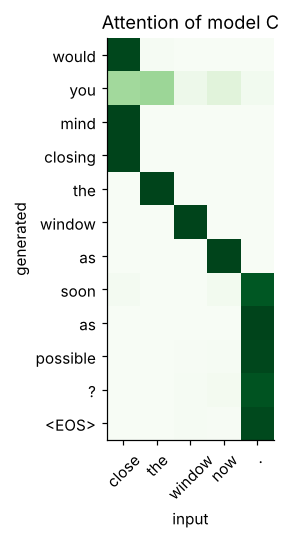

In [45]:
s = tokenize("Close the window now.")
r = greedy_decode(C, [s])[0]
att = r["attention"]
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(att, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(s)), s, rotation=45)
ax.set_yticks(range(att.shape[0]), (r["tokens"] + ["<EOS>"])[:att.shape[0]])
ax.set_xlabel("input")
ax.set_ylabel("generated")
ax.set_title("Attention of model C")
plt.tight_layout()
plt.show()

### 19.4 Human evaluation

The automatic success can be wrong: a sentence can be polite and keep the content words, yet be
ungrammatical or change the meaning. So the outputs of the final system were also judged by hand as
**acceptable / partial / failed**. There was one annotator only, and the labels were produced with
the help of an AI assistant. They should be confirmed by more annotators.

In [46]:
human = json.loads((REPORTS / "human_eval_summary.json").read_text())
pd.DataFrame([{"system / sentences": k, **v["counts"], "acceptable rate": v["acceptable_rate"],
               "automatic success": v["automatic_success"]} for k, v in human.items()]).fillna(0)

,system / sentences,acceptable,failed,partial,acceptable rate,automatic success
0,C_copy_nodrop__beam5,38,22.0,12,0.528,0.764
1,B_attention,12,56.0,4,0.167,0.222
2,"C_copy_nodrop__beam5 (test_unseen, random 40)",15,14.0,11,0.375,0.775
3,"C_copy_nodrop__beam5 (test, random 40)",39,0.0,1,0.975,0.975


### 19.5 Discussion and limits

**Does the model learn the task?** Yes. On sentences close to its training data, almost every
rewrite is correct (0.999 automatic success, 39 out of 40 acceptable by hand).

**Why does it fail?**
- It chooses the polite frame from a few **cue words**. An impolite opening it has never seen is
  sometimes copied as if it were content, or the frame does not fit. For example, a refusal can
  become a request: *"I won't lend you any more money"* → *"Would it be possible for you to lend you
  any more money?"*, where the meaning is reversed.
- **Grammar is not adapted**: tense errors (*"…could you pay the rent yesterday?"*) and pronouns.
- Long sentences with two ideas lose the second one, for example the reason in *"Give me my keys
  back, I need them right now"*.
- **The automatic metric is too optimistic** outside the training distribution (0.76 vs 0.53
  acceptable by hand on the challenge set), because it checks content words but not grammar or
  meaning.

**Limits of the approach**
- the phrasings come from a finite set of templates (108 impolite, 54 polite);
- a word-level vocabulary: unknown words can only be copied, never generated in another form;
- a bag-of-words politeness classifier as judge;
- a small human evaluation with one annotator.

**Possible improvements**: more varied data (real messages rewritten by hand), subword units (BPE),
a Transformer encoder–decoder with the same copy mechanism, a coverage penalty against repetitions,
and a larger human evaluation.

## 20. Conclusion

- A small encoder–decoder (1.67 M parameters) **implemented and trained from scratch** learns to
  rewrite impolite sentences politely while keeping their content.
- **Attention** speeds up learning and keeps more content. The **copy mechanism** is the most useful
  improvement: on hand-written sentences, the share of fully acceptable rewrites goes from 17 % (B)
  to 53 % (C), and the automatic success from 0.22 to 0.76.
- A bigger model did not help, but **better data did** (version 1 → version 2 of the dataset).
- **Lessons learned**: evaluate far from the training data (test_unseen, hand-written sentences), use
  several metrics, and check the metrics by hand.
- **Future work**: real data, subwords, a Transformer with copy, and more annotators.

The complete code, the trained models, the Streamlit interface (`streamlit run app.py`) and the
2-page report are in the project repository.